In [ ]:
import sys, os
sys.path.append("../app/")

import temframe
import matplotlib.pyplot as plt
import numpy as np
import torch, pandas as pd

In [ ]:
with open("C:/Users/au646858/Downloads/USF_Files_dawa river.zip", "rb") as f:
    raw_df_data = temframe.TEMframe.from_zip(f.read())

c:\Users\au646858\OneDrive - Aarhus universitet\Documents\_repositories\sea-anemone\prototyping\../app\temframe.py:168: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'N' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_data.loc[ok, 'zone_letter'] = zone_letter


In [3]:
# raw_df_data = raw_df_data[raw_df_data['site_id']<25]
raw_df_overview = raw_df_data.overview()

In [4]:
def silence(s):
    pass

from anemone.inversion import *
# fastJac = fastjacobian(dolphinv.Inversion)


#        res_start = LogResistivity.smooth(torch.ones(31)*40., torch.logspace(0, 2.1, 30))
raw_df_data._record_op()
current_history = raw_df_data.history.copy()

raw_df_data.forward_operators[0].source     = raw_df_data.forward_operators[1].source
raw_df_data.forward_operators[0].receiver   = raw_df_data.forward_operators[1].receiver
raw_df_data.forward_operators[0].filterfunc = raw_df_data.forward_operators[1].filterfunc

dmfwr = raw_df_data.forward_operators[0]+raw_df_data.forward_operators[1]

In [5]:
z = torch.cumsum(torch.logspace(0, np.log10(50.), 30), 0)
z /= z.max()
z *= 80.

res_start = LogResistivity.smooth(torch.ones(len(z)+1)*20., z)
dbdt = dmfwr(*res_start.mod)

In [6]:
# plt.figure()
from anemone import rdtype

with raw_df_data._skip_tracking():
    df_data     = raw_df_data.copy()
    df_overview = raw_df_data.overview()


    # this gives a warning and may need to updated if pandas is updated to pandas 3.0
    df_data['include'] = df_data['inuse_manual'].fillna(df_data['inuse_auto'])

    df_data['dbdt_syn'] = df_data['dbdt']*np.nan
    pivot_multi = df_data[(df_data['site_id']>-1)*(df_data['gate_id']>-1)].pivot_table(
        index=['site_id'],
        columns=['sys_gate'],
        values=['dbdt', 'error', 'include', 'data_id'],
    )
    pivot_multi['site_id'] = pivot_multi.index
    
    pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]

    assert len(pivot_multi) == len(df_overview), "Expected 4 columns in pivot_multi"

    pivot_multi.sort_values(by='site_id', inplace=True)
    df_overview.sort_values(by='site_id', inplace=True)        

    results  = []
    inv_list = []
    x_list   = []
    y_list   = []

    for i,((id_row, row), (id_meta, row_meta)) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
        assert id_meta == id_row, "Site ID mismatch between row and metadata"

        dbdt_values    = row.filter(like='dbdt_').values
        error_values   = row.filter(like='error_').values
        include_values = row.filter(like='include_').values
        data_id        = row.filter(like='data_id_').values
        
        d_obs = torch.from_numpy(dbdt_values).log().to(rdtype)
        # print(d_obs)
        d_err = torch.from_numpy(np.log1p(error_values/100.)).to(rdtype)
        d_err[dbdt_values <= 0] = torch.inf  # Set error to infinity for non-positive measurements
        # include_mask = include_values.astype(bool)
        # d_err[~include_mask] = torch.inf  # Set error to zero for included measurements

        inv1 = fastJac(d_obs, d_err, res_start, dmfwr, logger=print)
        inv_list.append(inv1.copy())
        x_list.append(row_meta['utm_x']*1.)
        y_list.append(row_meta['utm_y']*1.)
        # plt.semilogx(dmfwr.times, d_obs.numpy(), '-')

C:\Users\au646858\AppData\Local\Temp\ipykernel_11804\2643369029.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_data['include'] = df_data['inuse_manual'].fillna(df_data['inuse_auto'])


In [7]:
sci = SCI(inv_list, x=np.array(x_list), y=np.array(y_list))
sci.horizontal_smoothness = 0.6
res_mods = sci.invert(iter_cap=10)
#lci = LCI(inv_list)
#res_mods = lci.invert(iter_cap=10)

15  attempts  [np.float64(1.9223616108109856), np.float64(1.9221786470430706), np.float64(1.921756843879106), np.float64(1.9211242143829488), np.float64(1.9197656314342082), np.float64(1.9167207644520368), np.float64(1.910973674500688), np.float64(1.8993451603684235), np.float64(1.8733370518235448), np.float64(1.815444967009606), np.float64(1.7046338025857346), np.float64(1.7759850556536325), np.float64(1.714676646682954), np.float64(1.276011459854462), np.float64(0.6369173395219031)]
dMisfit:  -0.513626182413525
001	misfit:	237.88
data misfit:  210.90655085224608
1  attempts  [np.float64(0.44536292149050016)]
dMisfit:  -0.6064241864266315
002	misfit:	93.62
data misfit:  64.42844645623633
4  attempts  [np.float64(0.27526659282176935), np.float64(0.29303541055131394), np.float64(0.3310266993584041), np.float64(0.39589639740427585)]
dMisfit:  -0.54927492030152
003	misfit:	42.20
data misfit:  26.165332494408386
5  attempts  [np.float64(0.2548361946203701), np.float64(0.27036337045465386),

In [8]:
# lci_ctc = lci.CtC
sci_ctc = sci.CtC

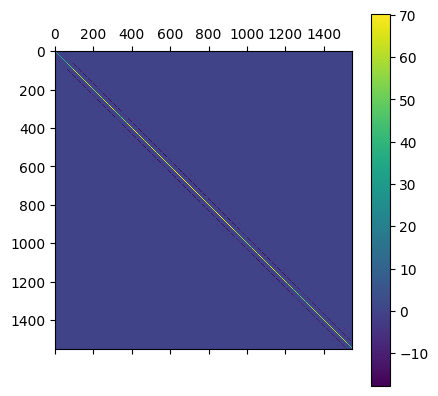

In [9]:
# pcm=plt.matshow(lci_ctc.toarray())
# plt.colorbar(pcm)

pcm=plt.matshow(sci_ctc.toarray())
plt.colorbar(pcm)

In [10]:
with df_data._skip_tracking():
    for i,((id_row, row), (id_meta, row_meta)) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
        assert id_meta == id_row, "Site ID mismatch between row and metadata"

        data_id = row.filter(like='data_id_').values    
        res_mod = res_mods[i].copy()

        d_syn = inv_list[i].forward(*res_mod.mod).exp()
        df_data.loc[data_id, 'dbdt_syn'] = d_syn.numpy()

        rho,thick = res_mod.mod
        row_meta['site_id'] = id_meta
        row_meta['resistivity'] = rho.detach().cpu().numpy().tolist()
        row_meta['thickness'] = thick.detach().cpu().numpy().tolist()
        
        results.append(row_meta.to_dict())
        print(f'Inversion for data_id {i:02d} completed.', flush=True, end='\r')

    df_resmod = pd.DataFrame(results)

    rows = []
    for _, row in df_resmod.iterrows():
        site_id = row['site_id']
        resistivities = row['resistivity']
        thicknesses = row['thickness']
        tops = np.concatenate([[0], np.cumsum(thicknesses)[:-1]])
        bottoms = np.cumsum(thicknesses)
        for i, (rho, top, bottom) in enumerate(zip(resistivities, tops, bottoms)):
            rows.append({
                'site_id': site_id,
                'daytime': row['daytime'],
                'date': row['date'],
                'latitude': row['latitude'],
                'longitude': row['longitude'],
                'elevation': row['elevation'],
                'layer': i,
                'resistivity': rho,
                'top_depth': top,
                'bottom_depth': bottom,
                'center_depth': (top + bottom) / 2
            })

    df_layers = df_data.__class__(rows, history=current_history.copy())
df_data.history = current_history[:-1]

In [11]:
df_layers_long = pd.melt(
    df_layers,
    id_vars=['site_id', 'daytime', 'longitude', 'latitude', 'date', 'elevation', 'layer', 'resistivity'],
    value_vars=['top_depth', 'bottom_depth'],
    var_name='depth_type',
    value_name='depth'
).sort_values(['daytime', 'layer', 'depth'])

# Optional: drop 'depth_type' if you don't need it
df_layers_long = df_layers_long.drop(columns=['depth_type'])

df_layers_long
df_layers_long['z'] = df_layers_long['elevation']-df_layers_long['depth']
df_layers_long['log_resistivity'] = np.log10(df_layers_long['resistivity'])

In [12]:
import plotly.express as px

# Ensure all site_ids are present as columns, even if some are missing
all_site_ids = np.arange(df_layers_long['site_id'].min(), df_layers_long['site_id'].max() + 1)
heatmap_df = df_layers_long.pivot_table(
    index='depth', columns='site_id', values='log_resistivity')
heatmap_df = heatmap_df.reindex(columns=all_site_ids)

# Sort depth so it increases downward
heatmap_df = heatmap_df.sort_index(ascending=True)

try:
    fig = px.imshow(
        heatmap_df,
        aspect='auto',
        origin='lower',
        color_continuous_scale='turbo',
        labels={'x': 'Site ID', 'y': 'Depth [m]', 'color': 'log10 Resistivity [Ω·m]'},
        title='Resistivity Heatmap by Site and Depth',
        zmin=heatmap_df.min().min(),
        zmax=heatmap_df.max().max(),
    )

    fig.update_yaxes(autorange="reversed")
except ValueError as e:
    print("caught exception:", e)
fig

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'coloraxis': 'coloraxis',
              'hovertemplate': 'Site ID: %{x}<br>Depth [m]: %{y}<br>log10 Resistivity [Ω·m]: %{z}<extra></extra>',
              'name': '0',
              'type': 'heatmap',
              'x': {'bdata': ('AAAAAAAAAAAAAAAAAADwPwAAAAAAAA' ... 'AAgEdAAAAAAAAASEAAAAAAAIBIQA=='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAAAAAAAABg503KPwAAAAAoNN' ... 'Dgil9OQAAAAIBkblFAAAAAAAAAVEA='),
                    'dtype': 'f8'},
              'yaxis': 'y',
              'z': {'bdata': ('3b3k24Yt7z+cfGAJJBbyPzH1RXx6vP' ... 'uVU+U/GGKyOvIQ5D9CeNr8PvDjPw=='),
                    'dtype': 'f8',
                    'shape': '31, 50'}}],
    'layout': {'coloraxis': {'cmax': np.float64(1.522619014036485),
                             'cmin': np.float64(0.546210840110968),
                             'colorbar': {'title': {'text': 'log10 Resistivity [Ω·m]'}},
                             'colorscale': [[0.0, '#30123b'],
                                            [0.07142857142857142, '#4145ab'],
                                            [0.14285714285714285, '#4675ed'],
                                            [0.21428571428571427, '#39a2fc'],
                                            [0.2857142857142857, '#1bcfd4'],
                                            [0.35714285714285715, '#24eca6'],
                                            [0.42857142857142855, '#61fc6c'], [0.5,
                                            '#a4fc3b'], [0.5714285714285714,
                                            '#d1e834'], [0.6428571428571429,
                                            '#f3c63a'], [0.7142857142857143,
                                            '#fe9b2d'], [0.7857142857142857,
                                            '#f36315'], [0.8571428571428571,
                                            '#d93806'], [0.9285714285714286,
                                            '#b11901'], [1.0, '#7a0402']]},
               'template': '...',
               'title': {'text': 'Resistivity Heatmap by Site and Depth'},
               'xaxis': {'anchor': 'y', 'domain': [0.0, 1.0], 'title': {'text': 'Site ID'}},
               'yaxis': {'anchor': 'x', 'autorange': 'reversed', 'domain': [0.0, 1.0], 'title': {'text': 'Depth [m]'}}}
})